<a href="https://colab.research.google.com/github/bbarraza11/spaceflight-muscle-health/blob/main/Muscle_Health_OSD104.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**🚀 Spaceflight and Muscle Health: OSD-104 (Soleus Muscle)**

#**Introduction**
In this notebook, we're using NASA's OSD-104 dataset to explore how spaceflight affects gene expression in the soleus muscle of mice. We'll compare mice that traveled to space with mice that stayed on Earth to see how their muscle gene activity differs.

#**Objectives**

The goal of this notebook is to explore how spaceflight affects gene expression in the soleus muscle of mice and what these changes might tell us about muscle health.

We'll use three methods to analyze the data:

**- Principal Component Analysis (PCA):** To see whether the spaceflight and ground-control mice show different patterns of gene expression.

**- Differential Gene Expression Analysis (DGEA):** To identify genes that are more or less active in mice that traveled to space compared to those that stayed on Earth.

**- Volcano Plot:** To visualize which genes show the largest and most statistically significant differences.

We'll then use these results alongside NASA's OSD-101 dataset, which studies the gastrocnemius muscle, to compare how the two muscles respond to spaceflight and look for similar patterns that could be related to muscle health or muscle atrophy.

# Prepare Runtime Environment

In [30]:
# Record the start time of the OSD-104 analysis
import datetime
start_time = datetime.datetime.now()
print('notebook start time: ', start_time.strftime('%Y-%m-%d %H:%M:%S'))

notebook start time:  2026-11-19 22:09:21


In [31]:
# # Connect Google Drive to save the analysis results
from google.colab import drive
drive.flush_and_unmount()
drive.mount("mnt")


Mounted at mnt


In [32]:
# Select NASA's OSD-104 soleus muscle dataset
OSD_DATASET='104'
GLDS_DATASET='104'


In [33]:
# define the threshold for coefficient of variation
CV_THRESH=0.5

In [34]:
# define log2 fold change threshold
LOG2FC_THRESH = 2

In [35]:
# define alpha level
ALPHA_LEVEL = 0.05

In [36]:
# Create a folder in Google Drive to store project results
import os

DGEA_DIR = '/content/mnt/MyDrive/Muscle_Health_Project'
os.makedirs(DGEA_DIR, exist_ok=True)


In [37]:
# Create a folder to store the OSD-104 sample metadata
import os
META_DIR=DGEA_DIR + "/META/" + OSD_DATASET
if os.path.exists(META_DIR):
  !rm -rf {META_DIR}
!mkdir -p {META_DIR}

In [38]:
# Install Python packages needed for gene expression analysis
!pip install \
  numpy \
  pandas==2.2.3 \
  scipy \
  numba \
  pydeseq2 \
  mygene \
  tsfresh \
  access \
  requests

# Install scikit-learn for principal component analysis (PCA)
!pip install scikit-learn > /dev/null


In [39]:
# Import libraries for gene expression analysis and PCA
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt


# Define Python Functions for Data Processing

In [40]:
# Remove rows with missing values from the gene expression data
def drop_nans(df):
  # drop NaN rows
  df = df.dropna(inplace=False)
  return df

In [41]:
# Define a function to remove genes with very low expression counts
def drop_lowcount(df, threshold=10):

  # let's drop any low-count genes
  if 'transcript' in df.columns:
    df = df[df.drop(columns=['transcript']).sum(axis=1) >= threshold]
  elif 'Unnamed: 0' in df.columns:
    df = df[df.drop(columns=['Unnamed: 0']).sum(axis=1) >= threshold]
  else:
    raise Exception("check file format")
  return df


In [42]:
# define method for filtering low coefficient-of-variation genes
def filter_cvs(df, thresh):
  import numpy as np
  import matplotlib.pyplot as plt

  # calculate coefficient of variation
  cvs=list()
  for i in range(len(df)):
    m = np.mean(df.iloc[i][1:])
    sd = np.std(df.iloc[i][1:])
    cvs.append(sd/m)

  # plot hist of dist of coev of variation
  fig, axs = plt.subplots()
  axs.hist(cvs, bins=20)

  # add labels for x and y axes
  plt.xlabel('coefficient of variation')
  plt.ylabel('number of genes')

  # keep genes with cv > thresh
  indices = list()
  for i in range(len(cvs)):
    if cvs[i] > thresh:
      indices.append(i)
  return df.iloc[indices]


In [43]:
# define method to transpose a dataframe
def transpose_df(df, cur_index_col, new_index_col):
  df = df.set_index(cur_index_col).T
  df.reset_index(level=0, inplace=True)
  cols = [new_index_col] + list(df.columns)[1:]
  df.columns = cols
  return df

In [44]:
# define method for dropping ERCC genes from dataframe
def drop_ercc(df):
  df = df[df['Unnamed: 0'].str.contains('ERCC-') == False]
  return df

In [45]:
# define method for running PCA
def run_pca(_expr, _meta):
  # first only keep "Ground Control" and "Space Flight" samples
  gc_samples = list(_meta[_meta['Factor Value[Spaceflight]'] == 'ground control']['Sample Name'])
  sf_samples = list(_meta[_meta['Factor Value[Spaceflight]'] == 'space flight']['Sample Name'])
  samples = gc_samples + sf_samples
  expr = _expr[_expr['sample'].isin(samples)]
  X = np.array(expr.drop(columns=['sample']))
  print('X shape: ', X.shape)
  factor_list = list()
  for sample in list(expr['sample']):
      factor_value = _meta[_meta['Sample Name'] == sample]['Factor Value[Spaceflight]'].values[0]
      factor_list.append(factor_value)
  y = np.array(list(factor_list))
  print('y shape: ', y.shape)
  target_names=np.array(['ground control', 'space flight'])

  # run PCA to reduce dimensions from 23,419 to 2!
  pca = PCA(n_components=2)
  X_r = pca.fit_transform(X)

  # Percentage of variance explained for each components
  print(
      "explained variance ratio (first two components): %s"
      % str(pca.explained_variance_ratio_)
  )

  # plot the pca plot
  plt.figure()
  colors = ["navy", "turquoise"]
  lw = 2
  for color, i, target_name in zip(colors, ['ground control', 'space flight'], target_names):
      plt.scatter(X_r[y == i, 0], X_r[y == i, 1], color=color, alpha=0.8, lw=lw, label=target_name)
  plt.legend(loc="best", shadow=False, scatterpoints=1)
  plt.title("PCA of OSD dataset")

  # show the last digits of the sample name if the number of samples is less than 40
  if len(expr) < 40:
    samples = list(expr['sample'])
    for i, txt in enumerate(samples):
        plt.annotate(txt[-16:], (X_r[i][0], X_r[i][1]))
  plt.show()


In [46]:
!pip install mygene
def get_symbol_from_id(gene_id_list):
  import mygene

  # Initialize the mygene client
  mg = mygene.MyGeneInfo()


  # Perform the batch lookup
  query_results = mg.querymany(
    gene_id_list,
    scopes="ensembl.gene",  # Change based on input format (e.g., 'entrezgene', 'refseq')
    fields="symbol",        # Request the official gene symbol
    species="mouse"         # Restrict to mouse genes
  )

  results=list()
  # Parse and display the results
  for res in query_results:
    query_id = res.get("query")
    symbol = res.get("symbol", query_id)  # 'N/A' if mapping failed
    #print(f"ID: {query_id} -> Symbol: {symbol}")
    results.append(symbol)

  return results


# Download data from OSDR

In [47]:
# open the URL printed below in another browser window
url = !echo https://visualization.osdr.nasa.gov/biodata/api/v2/dataset/OSD-{OSD_DATASET}/files/\?format=browser
print(url[0])

https://visualization.osdr.nasa.gov/biodata/api/v2/dataset/OSD-104/files/?format=browser


In [48]:
# download OSD unnormalized count data
import pandas as pd
url = 'https://osdr.nasa.gov/geode-py/ws/studies/OSD-' + OSD_DATASET + '/download?source=datamanager&file=GLDS-' + GLDS_DATASET + '_rna_seq_Unnormalized_Counts.csv'
expr_df = pd.read_csv(url)
expr_df.head()

,Unnamed: 0,Mmus_C57-6J_SLS_FLT_Rep1_M23,Mmus_C57-6J_SLS_FLT_Rep2_M24,Mmus_C57-6J_SLS_FLT_Rep3_M25,Mmus_C57-6J_SLS_FLT_Rep4_M26,Mmus_C57-6J_SLS_FLT_Rep5_M27,Mmus_C57-6J_SLS_FLT_Rep6_M28,Mmus_C57-6J_SLS_GC_Rep1_M33,Mmus_C57-6J_SLS_GC_Rep2_M34,Mmus_C57-6J_SLS_GC_Rep3_M35,Mmus_C57-6J_SLS_GC_Rep4_M36,Mmus_C57-6J_SLS_GC_Rep5_M37,Mmus_C57-6J_SLS_GC_Rep6_M38
0,ENSMUSG00000000001,869.0,706.0,835.0,871.0,1069.0,700.0,1205.0,908.0,1078.0,877.0,884.0,911.0
1,ENSMUSG00000000003,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,ENSMUSG00000000028,91.0,121.0,87.0,139.0,193.0,104.0,145.0,117.0,135.0,114.0,128.0,130.0
3,ENSMUSG00000000031,68226.0,64898.0,85595.0,90775.0,71300.0,56376.0,143726.0,104717.0,128088.0,115071.0,108243.0,118878.0
4,ENSMUSG00000000037,7.0,8.0,9.0,11.0,11.0,5.0,21.0,10.0,10.0,5.0,3.0,16.0


In [49]:
# identify the shape of the expr_df dataframe
expr_df.shape

(55536, 13)

In [50]:
# call drop_ercc
# there may or may not be ERCC records to drop
expr_df = drop_ercc(expr_df)
expr_df.shape

(55536, 13)

In [51]:
# call drop_nans
# there may or may not be NaNs to drop
expr_df = drop_nans(expr_df)
expr_df.shape

(55536, 13)

In [52]:
# call drop_lowcount with threshold=50
expr_df = drop_lowcount(expr_df, threshold=50)
expr_df.shape

(17690, 13)

(2104, 13)

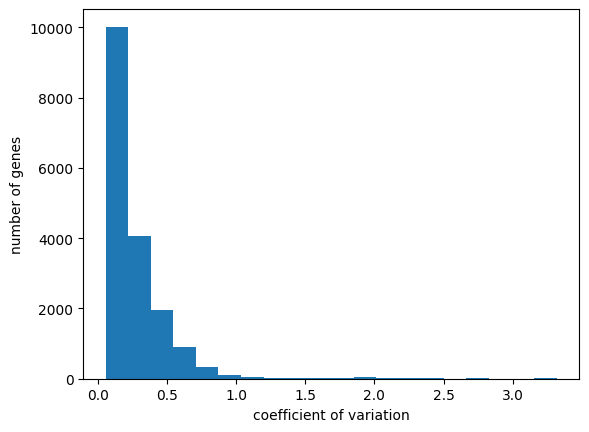

In [53]:
# call filter_cvs with thresh=CV_THRESH
expr_df = filter_cvs(expr_df, thresh=CV_THRESH)
expr_df.shape

In [54]:
# Save the filtered OSD-104 gene expression data to Google Drive
expr_df.to_csv(DGEA_DIR + '/expr_df.csv', sep=',', index=None)

In [55]:
# then transpose expr_df to be samples x genes
expr_df = transpose_df(expr_df, 'Unnamed: 0', 'sample')
expr_df.head()

,sample,ENSMUSG00000000049,ENSMUSG00000000167,ENSMUSG00000000204,ENSMUSG00000000214,ENSMUSG00000000247,ENSMUSG00000000303,ENSMUSG00000000308,ENSMUSG00000000385,ENSMUSG00000000386,...,ENSMUSG00000118101,ENSMUSG00000118132,ENSMUSG00000118161,ENSMUSG00000118206,ENSMUSG00000118229,ENSMUSG00000118232,ENSMUSG00000118249,ENSMUSG00000118292,ENSMUSG00000118317,ENSMUSG00000118353
0,Mmus_C57-6J_SLS_FLT_Rep1_M23,11.0,15.0,0.0,6.0,7.0,64.0,8.0,36.0,6.0,...,1.0,1.0,7.62,9.0,3.0,5.0,3.0,26.0,7.0,2.84
1,Mmus_C57-6J_SLS_FLT_Rep2_M24,11.0,3.0,3.0,37.0,12.0,113.0,13.0,3.0,4.0,...,1.0,3.0,0.00,7.0,0.0,0.0,11.0,26.0,6.0,1.37
2,Mmus_C57-6J_SLS_FLT_Rep3_M25,23.0,5.0,4.0,16.0,10.0,77.0,13.0,12.0,4.0,...,7.0,10.0,4.23,1.0,7.0,5.0,8.0,28.0,13.0,5.11
3,Mmus_C57-6J_SLS_FLT_Rep4_M26,18.0,3.0,8.0,12.0,20.0,76.0,7.0,15.0,9.0,...,12.0,5.0,3.58,4.0,2.0,5.0,12.0,19.0,8.0,5.11
4,Mmus_C57-6J_SLS_FLT_Rep5_M27,66.0,5.0,18.0,16.0,12.0,33.0,2.0,11.0,16.0,...,7.0,5.0,2.09,13.0,22.0,6.0,6.0,17.0,15.0,6.15


In [56]:
# determine the shape of the expr_df_T dataframe
expr_df.shape

(12, 2105)

In [57]:
# read in  metadata
url = 'https://osdr.nasa.gov/geode-py/ws/studies/OSD-' + OSD_DATASET + \
  '/download\?source=datamanager\&file=OSD-' + OSD_DATASET + '_metadata_OSD-' + GLDS_DATASET + '-ISA.zip'

!curl -L {url} -o {META_DIR}/metadata-{OSD_DATASET}.zip
!unzip -o {META_DIR}/metadata-{OSD_DATASET}.zip -d {META_DIR}

<>:3: SyntaxWarning: invalid escape sequence '\?'
<>:3: SyntaxWarning: invalid escape sequence '\?'
/tmp/ipykernel_1773/2785228226.py:3: SyntaxWarning: invalid escape sequence '\?'
  '/download\?source=datamanager\&file=OSD-' + OSD_DATASET + '_metadata_OSD-' + GLDS_DATASET + '-ISA.zip'


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  3746  100  3746    0     0   3381      0  0:00:01  0:00:01 --:--:--  3380
100 81627  100 81627    0     0  47873      0  0:00:01  0:00:01 --:--:-- 47873
Archive:  /content/mnt/MyDrive/Muscle_Health_Project/META/104/metadata-104.zip
 extracting: /content/mnt/MyDrive/Muscle_Health_Project/META/104/s_OSD-104.txt  
 extracting: /content/mnt/MyDrive/Muscle_Health_Project/META/104/i_Investigation.txt  
 extracting: /content/mnt/MyDrive/Muscle_Health_Project/META/104/a_OSD-104_transcription-profiling_rna-sequencing-(rna-seq)_Illumina.txt  
 extracting: /content/mnt/MyDrive/Muscle_Health_Project/META/104/a_OSD-104_dna-methylation-profiling_whole-genome-bisulfite-sequencing_Illumina.txt  


In [58]:
# check metadata
meta_df = pd.read_csv(f"{META_DIR}/s_OSD-" + OSD_DATASET + ".txt", sep='\t')
meta_df.head()

,Source Name,Sample Name,Characteristics[Organism],Term Source REF,Term Accession Number,Characteristics[Strain],Term Source REF.1,Term Accession Number.1,Characteristics[Animal Source],Characteristics[Sex],...,Unit.4,Term Source REF.13,Term Accession Number.13,Parameter Value[absorbed radiation dose rate],Unit.5,Term Source REF.14,Term Accession Number.14,Parameter Value[ionizing radiation categorized by source],Term Source REF.15,Term Accession Number.15
0,RR1_GC_M33,Mmus_C57-6J_SLS_GC_Rep1_M33,Mus musculus,NCBITAXON,http://purl.bioontology.org/ontology/NCBITAXON...,C57BL/6J,EFO,http://www.ebi.ac.uk/efo/EFO_0000606,Jackson Laboratory,Female,...,Not Applicable,OSD,https://osdr.nasa.gov/,NaN,Not Applicable,OSD,https://osdr.nasa.gov/,Not Applicable,NCIT,http://purl.obolibrary.org/obo/NCIT_C48660
1,RR1_GC_M34,Mmus_C57-6J_SLS_GC_Rep2_M34,Mus musculus,NCBITAXON,http://purl.bioontology.org/ontology/NCBITAXON...,C57BL/6J,EFO,http://www.ebi.ac.uk/efo/EFO_0000606,Jackson Laboratory,Female,...,Not Applicable,OSD,https://osdr.nasa.gov/,NaN,Not Applicable,OSD,https://osdr.nasa.gov/,Not Applicable,NCIT,http://purl.obolibrary.org/obo/NCIT_C48660
2,RR1_GC_M35,Mmus_C57-6J_SLS_GC_Rep3_M35,Mus musculus,NCBITAXON,http://purl.bioontology.org/ontology/NCBITAXON...,C57BL/6J,EFO,http://www.ebi.ac.uk/efo/EFO_0000606,Jackson Laboratory,Female,...,Not Applicable,OSD,https://osdr.nasa.gov/,NaN,Not Applicable,OSD,https://osdr.nasa.gov/,Not Applicable,NCIT,http://purl.obolibrary.org/obo/NCIT_C48660
3,RR1_GC_M36,Mmus_C57-6J_SLS_GC_Rep4_M36,Mus musculus,NCBITAXON,http://purl.bioontology.org/ontology/NCBITAXON...,C57BL/6J,EFO,http://www.ebi.ac.uk/efo/EFO_0000606,Jackson Laboratory,Female,...,Not Applicable,OSD,https://osdr.nasa.gov/,NaN,Not Applicable,OSD,https://osdr.nasa.gov/,Not Applicable,NCIT,http://purl.obolibrary.org/obo/NCIT_C48660
4,RR1_GC_M37,Mmus_C57-6J_SLS_GC_Rep5_M37,Mus musculus,NCBITAXON,http://purl.bioontology.org/ontology/NCBITAXON...,C57BL/6J,EFO,http://www.ebi.ac.uk/efo/EFO_0000606,Jackson Laboratory,Female,...,Not Applicable,OSD,https://osdr.nasa.gov/,NaN,Not Applicable,OSD,https://osdr.nasa.gov/,Not Applicable,NCIT,http://purl.obolibrary.org/obo/NCIT_C48660


In [59]:
# change Factor Value[Spaceflight] to lower case
for i in range(len(meta_df)):
  meta_df.loc[i, 'Factor Value[Spaceflight]'] = meta_df.iloc[i]['Factor Value[Spaceflight]'].lower().strip()

In [60]:
# see how many samples are flight and how many are ground
meta_df['Factor Value[Spaceflight]'].value_counts()

,count
Factor Value[Spaceflight],
ground control,6
space flight,6


In [61]:
# drop all values from expr_df and meta_df that are not either "Ground Control" or "Space Flight"
gc_samples = list(meta_df[meta_df['Factor Value[Spaceflight]'] == 'ground control']['Sample Name'])
sf_samples = list(meta_df[meta_df['Factor Value[Spaceflight]'] == 'space flight']['Sample Name'])
samples = gc_samples + sf_samples
expr_df = expr_df[expr_df['sample'].isin(samples)]
meta_df = meta_df[meta_df['Sample Name'].isin(samples)]

In [62]:
# check shape of final dataframes prior to analysis
print('expr shape: ', expr_df.shape)
print('meta shape: ', meta_df.shape)

expr shape:  (12, 2105)
meta shape:  (12, 71)


# Run PCA

We use Principal Component Analysis (PCA) to see whether the gene expression patterns are different between the spaceflight and ground-control mice. This helps us visualize how the two groups compare in the soleus muscle.

X shape:  (12, 2104)
y shape:  (12,)
explained variance ratio (first two components): [0.9780037  0.02020145]


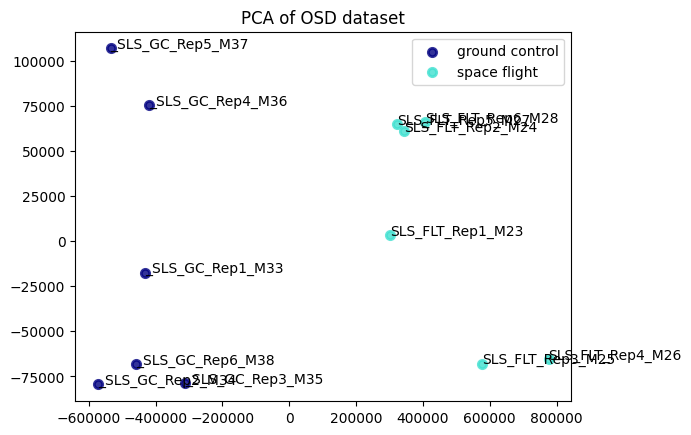

In [63]:
# call run_pca on expr_df_final
run_pca(expr_df, meta_df)

The PCA plot shows a clear separation between the spaceflight and ground-control mice in the soleus muscle dataset. The spaceflight samples are grouped on the right, while the ground-control samples are on the left. The first principal component explains about 97.8% of the variation in the filtered gene-expression data.

This suggests that spaceflight is associated with differences in gene expression in the soleus muscle. We'll use differential gene expression analysis to identify which genes changed and explore whether those changes may be related to muscle health or atrophy.


# Perform differential gene expression analysis

In [75]:
# First let's create a conditions table for 'Factor Value: Spaceflight'.
# We'll assign 0 for ground control and 1 for spaceflight
condition_dict=dict()
for sample in list(expr_df['sample']):
    val = meta_df[meta_df['Sample Name']==sample]['Factor Value[Spaceflight]'].values[0]
    if val.lower().strip() == 'ground control':
        condition_dict[sample] = 0
    elif val.lower().strip() == 'space flight':
        condition_dict[sample] = 1
    else:
      print('val ' + val + ' neither Ground Control nor Space Flight')
conditions =  pd.DataFrame.from_dict(condition_dict, orient='index')
conditions.columns = ['condition']


In [77]:
# Verify that each mouse sample is assigned to the correct experimental group
for i in range(len(meta_df)):
    sample = meta_df.iloc[i]['Sample Name']
    group = meta_df.iloc[i]['Factor Value[Spaceflight]']
    print(sample, group, conditions.loc[sample, 'condition'])

Mmus_C57-6J_SLS_GC_Rep1_M33 ground control 0
Mmus_C57-6J_SLS_GC_Rep2_M34 ground control 0
Mmus_C57-6J_SLS_GC_Rep3_M35 ground control 0
Mmus_C57-6J_SLS_GC_Rep4_M36 ground control 0
Mmus_C57-6J_SLS_GC_Rep5_M37 ground control 0
Mmus_C57-6J_SLS_GC_Rep6_M38 ground control 0
Mmus_C57-6J_SLS_FLT_Rep1_M23 space flight 1
Mmus_C57-6J_SLS_FLT_Rep2_M24 space flight 1
Mmus_C57-6J_SLS_FLT_Rep3_M25 space flight 1
Mmus_C57-6J_SLS_FLT_Rep4_M26 space flight 1
Mmus_C57-6J_SLS_FLT_Rep5_M27 space flight 1
Mmus_C57-6J_SLS_FLT_Rep6_M28 space flight 1


In [66]:
# make sure there are exactly 2 conditions for DGEA
set(meta_df['Factor Value[Spaceflight]'])


{'ground control', 'space flight'}

In [67]:
# create dataframe with 'sample' column removed for DESeq2
import numpy as np
counts = expr_df.drop(columns=['sample']).reset_index(drop=True)
# check for non-numeric
counts.applymap(np.isreal)
# convert all cells to integers
counts = counts.astype(int)
counts.shape

(12, 2104)

In [78]:
# Compare gene expression in spaceflight mice (1) against ground-control mice (0)
# store the results in a dataframe called "res"
dds = DeseqDataSet(counts=counts, metadata=conditions, design_factors="condition")
dds.deseq2()
stats_results = DeseqStats(dds, contrast=('condition', 1, 0))
stats_results.summary()
res = stats_results.results_df

Using None as control genes, passed at DeseqDataSet initialization


/tmp/ipykernel_1773/37893227.py:3: DeprecationWarning: design_factors is deprecated and will soon be removed.Please consider providing a formulaic formula using the design argumentinstead.
  dds = DeseqDataSet(counts=counts, metadata=conditions, design_factors="condition")
Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 3.10 seconds.

Fitting dispersion trend curve...
/usr/local/lib/python3.13/dist-packages/pydeseq2/dds.py:822: UserWarning: The dispersion trend curve fitting did not converge. Switching to a mean-based dispersion trend.
  self._fit_parametric_dispersion_trend(vst)
... done in 0.10 seconds.

Fitting MAP dispersions...
... done in 4.92 seconds.

Fitting LFCs...
... done in 2.07 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.

Running Wald tests...


Log2 fold change & Wald test p-value: condition 1 vs 0
                     baseMean  log2FoldChange     lfcSE      stat  \
ENSMUSG00000000049  15.571456        0.879139  0.489732  1.795143   
ENSMUSG00000000167   8.375381       -0.527831  0.580327 -0.909541   
ENSMUSG00000000204   5.093550       -0.120478  0.923265 -0.130491   
ENSMUSG00000000214  13.560621        0.330743  0.554538  0.596431   
ENSMUSG00000000247  10.081343       -0.167460  0.520320 -0.321840   
...                       ...             ...       ...       ...   
ENSMUSG00000118232   4.506685       -0.887308  0.685061 -1.295226   
ENSMUSG00000118249   6.297331        0.255434  0.567883  0.449801   
ENSMUSG00000118292  14.765490        1.221159  0.507039  2.408413   
ENSMUSG00000118317  23.313326       -2.126669  0.371385 -5.726322   
ENSMUSG00000118353   3.805923       -0.771506  0.689972 -1.118170   

                          pvalue          padj  
ENSMUSG00000000049  7.263097e-02  2.329881e-01  
ENSMUSG00000000167

... done in 0.59 seconds.



In [69]:
# Identify genes with adjusted p-value < 0.05 and absolute log2 fold change > 2
sigs = res[(res.padj < ALPHA_LEVEL) & (abs(res.log2FoldChange) > LOG2FC_THRESH)]
print(sigs.shape)
sigs.head()
sigs.to_csv(DGEA_DIR + '/sigs.csv', sep=',')

(159, 6)


In [70]:
# write differentially expressed gene list to file
deg_genes = list(sigs.index)
with open(f"{DGEA_DIR}/deg_genes-" + OSD_DATASET + ".txt", "w") as f:
  for gene in deg_genes:
    f.write(gene + "\n")
f.close()

# check gene file
!head {DGEA_DIR}/deg_genes-{OSD_DATASET}.txt

ENSMUSG00000000308
ENSMUSG00000000567
ENSMUSG00000001510
ENSMUSG00000002910
ENSMUSG00000006576
ENSMUSG00000015090
ENSMUSG00000015401
ENSMUSG00000015599
ENSMUSG00000016179
ENSMUSG00000018486


In [71]:
# write list of background genes to file
bg_genes = list(expr_df.drop(columns=['sample']))
with open(f"{DGEA_DIR}/background_genes-" + OSD_DATASET + ".txt", "w") as f:
  for gene in bg_genes:
    f.write(gene + "\n")
f.close()

# check gene file
!head {DGEA_DIR}/background_genes-{OSD_DATASET}.txt

ENSMUSG00000000049
ENSMUSG00000000167
ENSMUSG00000000204
ENSMUSG00000000214
ENSMUSG00000000247
ENSMUSG00000000303
ENSMUSG00000000308
ENSMUSG00000000385
ENSMUSG00000000386
ENSMUSG00000000409


# Create volcano plot



INFO:biothings.client:querying 1-10 ...
INFO:biothings.client:Finished.
INFO:biothings.client:Pass "returnall=True" to return complete lists of duplicate or missing query terms.


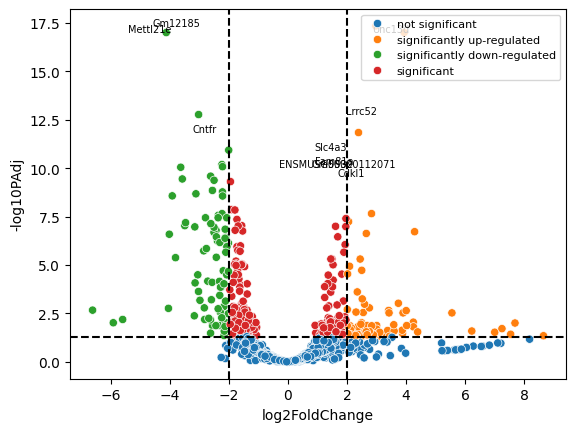

In [79]:

# import Python modules for plotting volcano
import pandas
import numpy
import matplotlib.pyplot as plt
import seaborn

# create column for -log10PAdj from existing padj
res['-log10PAdj'] = -numpy.log10(res['padj'])
pvalue_cutoff = -numpy.log10(ALPHA_LEVEL)

# create column for significance from existing log2FoldChange and -log10PAdj
significance = []
for i in range(len(res)):
    if res.iloc[i]['log2FoldChange'] > LOG2FC_THRESH and res.iloc[i]['-log10PAdj'] > pvalue_cutoff:
        significance.append('significantly up-regulated')
    elif res.iloc[i]['log2FoldChange'] < -LOG2FC_THRESH and res.iloc[i]['-log10PAdj'] > pvalue_cutoff:
        significance.append('significantly down-regulated')
    elif res.iloc[i]['padj'] < ALPHA_LEVEL:
        significance.append('significant')
    else:
        significance.append('not significant')

res['significance'] = significance
# plot the degs
plot1 = seaborn.scatterplot(res, x = "log2FoldChange", y = "-log10PAdj", hue = "significance")

# sort to get top 10 significant genes
top10 = sigs[sigs['padj'] < ALPHA_LEVEL].sort_values(by=['padj', 'log2FoldChange'], ascending=[True, False]).head(10)

# add gene_symbol to top10
gene_symbol_list = get_symbol_from_id(list(top10.index))
top10['gene_symbol'] = gene_symbol_list

# add -log10PAdj to top10
top10['-log10PAdj'] = -numpy.log10(top10['padj'])

# annotate top 10 significant genes
for i in range(top10.shape[0]):
    gene = top10.iloc[i]
    plt.text(gene['log2FoldChange'], gene['-log10PAdj'], gene['gene_symbol'], fontsize=7, ha='right')

# draw a horizontal line at the adjusted p-value threshold of 0.05
plt.axhline(y = pvalue_cutoff, color='black', linestyle='--')

# draw 2 lines at fold change threshold
plt.axvline(x = LOG2FC_THRESH, color = 'black', linestyle='--')
plt.axvline(x = -LOG2FC_THRESH, color='black', linestyle='--')

# set font size for legend
plt.legend(fontsize=8)


The horizontal dashed line represents the adjusted p-value significance threshold of 0.05, which corresponds to approximately 1.3 on the -log10 scale. The two vertical dashed lines represent log2 fold-change thresholds of -2 and +2. Genes outside these vertical lines and above the horizontal line are considered significantly up-regulated or down-regulated in spaceflight mice compared to ground controls.

In [73]:
sigs

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
ENSMUSG00000000308,4.820414,-2.448171,0.795020,-3.079382,2.074307e-03,1.691358e-02
ENSMUSG00000000567,1260.792252,2.013475,0.358486,5.616615,1.947351e-08,7.262898e-07
ENSMUSG00000001510,6.460441,-3.883514,1.381168,-2.811761,4.927107e-03,3.386755e-02
ENSMUSG00000002910,1148.829888,-2.055559,0.334742,-6.140728,8.214411e-10,5.704767e-08
ENSMUSG00000006576,786.372675,2.003514,0.264344,7.579201,3.476886e-14,1.167075e-11
...,...,...,...,...,...,...
ENSMUSG00000116597,5.501568,-2.471409,0.763147,-3.238444,1.201838e-03,1.131075e-02
ENSMUSG00000116725,16.483220,3.150681,0.524991,6.001405,1.956177e-09,1.064795e-07
ENSMUSG00000116851,47.623784,-2.088961,0.413996,-5.045846,4.515181e-07,1.151085e-05
ENSMUSG00000117313,29.324407,-2.022712,0.416676,-4.854405,1.207486e-06,2.861032e-05


# Check your work before moving on

In [74]:
# time the notebook
import datetime
end_time = datetime.datetime.now()
print('notebook end time: ', end_time.strftime('%Y-%m-%d %H:%M:%S'))

print('notebook runtime: ', end_time - start_time)
#

notebook end time:  2026-11-19 22:10:39
notebook runtime:  0:01:18.625491
